
# Netflix Business Insights Report

---


## Report Overview

This notebook consolidates the findings from the previous analytical notebooks into a comprehensive Business Intelligence report.

The report focuses on integrating key findings across content type, geographic distribution, release year trends, content ratings, and genre analysis to identify broader catalog patterns and potential business opportunities.

---



### Objectives

1. Integrate findings from previous Netflix content analyses.
2. Identify significant patterns across different content dimensions.
3. Evaluate the overall composition and characteristics of the Netflix content catalog.
4. Generate business insights based on analytical findings.
5. Develop data-driven recommendations.
6. Present key findings through interactive dashboards and an analytical report.

### Dataset

The analysis uses the cleaned Netflix dataset generated in Notebook 01, supported by findings from the previous analytical notebooks.

### Tools & Libraries

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Plotly
- Power BI

### Expected Deliverables

- Integrated Netflix content analysis.
- Executive summary of key findings.
- Business insights and recommendations.
- Interactive analytical dashboards.
- Comprehensive business insights report.

---



## Data Loading & Preparation

This section loads the cleaned Netflix dataset generated in Notebook 01 and performs basic validation to ensure data consistency and readiness for integrated analysis.


In [1]:

# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from pathlib import Path

# Set display options
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', '{:.2f}'.format)

sns.set_theme(style='whitegrid')



### Load Cleaned Dataset

Load the cleaned Netflix dataset produced in Notebook 01. This dataset serves as the primary data source for the integrated business analysis.


In [2]:

# Define dataset path
file_path = Path("../Dataset/Cleaned_Netflix_Data.csv")

# Load cleaned dataset
df = pd.read_csv(file_path)

# Display dataset preview
display(df.head())


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"



### Dataset Structure Validation

Inspect the dataset dimensions, column names, data types, and missing values to verify that the cleaned dataset is ready for further analysis.


In [3]:

# Check dataset dimensions
print(f"Dataset Shape: {df.shape}")

# Check column names
print("\nColumn Names:")
print(df.columns.tolist())

# Check data types and non-null values
print("\nDataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
display(df.isnull().sum())


Dataset Shape: (8786, 10)

Column Names:
['show_id', 'type', 'title', 'director', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8786 entries, 0 to 8785
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8786 non-null   object
 1   type          8786 non-null   object
 2   title         8785 non-null   object
 3   director      6199 non-null   object
 4   country       8499 non-null   object
 5   date_added    8786 non-null   object
 6   release_year  8786 non-null   int64 
 7   rating        8786 non-null   object
 8   duration      8786 non-null   object
 9   listed_in     8786 non-null   object
dtypes: int64(1), object(9)
memory usage: 686.5+ KB

Missing Values:


show_id            0
type               0
title              1
director        2587
country          287
date_added         0
release_year       0
rating             0
duration           0
listed_in          0
dtype: int64


### Data Quality Validation

Perform additional checks on duplicate records, unique identifiers, and data consistency to confirm that the cleaned dataset maintains its expected quality.


In [4]:

# Check exact duplicate records
exact_duplicates = df.duplicated().sum()

# Check duplicate show IDs
duplicate_show_ids = df['show_id'].duplicated().sum()

# Check duplicate metadata records, excluding show_id
metadata_duplicates = df.duplicated(
    subset=df.columns.drop('show_id')
).sum()

# Check unique values in key categorical columns
unique_content_types = df['type'].nunique()
unique_ratings = df['rating'].nunique()
unique_countries = df['country'].nunique()

# Display validation results
print(f"Exact Duplicate Records: {exact_duplicates}")
print(f"Duplicate Show IDs: {duplicate_show_ids}")
print(f"Duplicate Metadata Records: {metadata_duplicates}")

print(f"\nUnique Content Types: {unique_content_types}")
print(f"Unique Ratings: {unique_ratings}")
print(f"Unique Country Entries: {unique_countries}")


Exact Duplicate Records: 0
Duplicate Show IDs: 0
Duplicate Metadata Records: 0

Unique Content Types: 2
Unique Ratings: 14
Unique Country Entries: 85



### Data Type Preparation

Convert the `date_added` column into a datetime format to ensure that date-related information can be processed consistently in subsequent analysis.


In [5]:

# Convert date_added to datetime
df['date_added'] = pd.to_datetime(
    df['date_added'],
    errors='coerce'
)

# Verify data types
print("Updated Data Types:")
print(df.dtypes)

# Check date conversion results
print("\nDate Conversion Validation:")
print(f"Missing Dates: {df['date_added'].isnull().sum()}")


Updated Data Types:
show_id                 object
type                    object
title                   object
director                object
country                 object
date_added      datetime64[ns]
release_year             int64
rating                  object
duration                object
listed_in               object
dtype: object

Date Conversion Validation:
Missing Dates: 0


### Data Preparation Summary

The cleaned dataset contains 8,786 records and 10 columns. Data quality validation confirms that no duplicate records, duplicate show IDs, or duplicate metadata entries remain.

The dataset contains two content types, 14 rating categories, and 85 unique country entries. The `date_added` column has also been successfully converted into datetime format without introducing additional missing values.

The dataset is now ready for integrated analysis and business insight development. Existing missing values in the `title`, `director`, and `country` columns are retained because they do not prevent the overall analysis and will be considered when relevant to specific analytical dimensions.

## Executive Summary

This report provides an integrated analysis of Netflix's content catalog based on 8,786 records. The analysis examines content type distribution, geographic representation, release year trends, content ratings, and genre composition.

The findings highlight several characteristics of the catalog:

1. **Content Type Distribution:** Movies account for 69.69% of the catalog, while TV Shows represent 30.31%, indicating a larger representation of movie titles.
2. **Geographic Representation:** The United States represents 38.12% of records with available country information. Together, the five most represented countries account for 66.18% of those records.
3. **Release Year Trends:** Content released in 2018 represents the largest annual group, with 1,144 titles. The distribution indicates a strong concentration of titles released in more recent years.
4. **Content Ratings:** TV-MA is the most common rating category, accounting for 36.47% of the catalog, followed by TV-14 at 24.53%.
5. **Genre Composition:** International Movies (31.31%), Dramas (27.58%), and Comedies (19.04%) are the three most frequently represented genre labels.

Overall, the analysis shows that Netflix's catalog is characterized by a higher proportion of movies, substantial geographic concentration, and a diverse range of ratings and genres.

These findings provide a basis for understanding catalog composition and identifying areas for further content portfolio evaluation.

**Important Note:** This analysis is based on content metadata. The findings describe catalog representation and classification, not actual audience preferences, viewing behavior, production volume, or content performance.

## Integrated Content Analysis

This section combines the key analytical dimensions examined in the previous notebooks to provide a consolidated view of Netflix's content catalog.

The analysis focuses on the overall catalog composition, geographic representation, release year distribution, content ratings, and genre diversity.

By integrating these dimensions, this section aims to identify broader catalog patterns and provide a stronger foundation for business insights and recommendations.

### Key Catalog Metrics

This subsection presents the key metrics that summarize the overall characteristics of the Netflix content catalog.

In [6]:
# Calculate key catalog metrics

total_titles = len(df)

content_type_counts = df['type'].value_counts()
movie_count = content_type_counts.get('Movie', 0)
tv_show_count = content_type_counts.get('TV Show', 0)

country_available = df['country'].notna().sum()
country_missing = df['country'].isna().sum()

# Extract individual genre labels
genre_counts = (
    df['listed_in']
    .dropna()
    .str.split(',')
    .explode()
    .str.strip()
    .value_counts()
)

# Identify the most common categories
top_rating = df['rating'].value_counts().idxmax()
top_genre = genre_counts.idxmax()

# Identify the most common release year
release_year_counts = df['release_year'].value_counts()
most_common_release_year = release_year_counts.idxmax()
most_common_release_year_count = release_year_counts.max()

# Create summary table
summary_metrics = pd.DataFrame({
    'Metric': [
        'Total Titles',
        'Movies',
        'TV Shows',
        'Movie Proportion (%)',
        'TV Show Proportion (%)',
        'Country Information Available',
        'Missing Country Information',
        'Unique Country Entries',
        'Unique Rating Categories',
        'Unique Genre Labels',
        'Most Common Rating',
        'Most Represented Genre',
        'Most Common Release Year',
        'Titles in Most Common Release Year'
    ],
    'Value': [
        total_titles,
        movie_count,
        tv_show_count,
        movie_count / total_titles * 100,
        tv_show_count / total_titles * 100,
        country_available,
        country_missing,
        df['country'].nunique(),
        df['rating'].nunique(),
        len(genre_counts),
        top_rating,
        top_genre,
        most_common_release_year,
        most_common_release_year_count
    ]
})

display(summary_metrics)

,Metric,Value
0,Total Titles,8786
1,Movies,6123
2,TV Shows,2663
3,Movie Proportion (%),69.69
4,TV Show Proportion (%),30.31
5,Country Information Available,8499
6,Missing Country Information,287
7,Unique Country Entries,85
8,Unique Rating Categories,14
9,Unique Genre Labels,42


### Content Portfolio Composition

This subsection examines how Movies and TV Shows differ in their rating classifications and genre representation.

The comparison helps identify the distinct characteristics of each content type within the Netflix catalog.

In [7]:
# Calculate rating distribution by content type
rating_comparison = pd.crosstab(
    df['rating'],
    df['type'],
    normalize='columns'
) * 100

# Sort ratings by overall frequency
rating_order = df['rating'].value_counts().index
rating_comparison = rating_comparison.reindex(rating_order)

display(rating_comparison.round(2))

type,Movie,TV Show
rating,,
TV-MA,33.66,42.92
TV-14,23.29,27.38
TV-PG,8.82,12.05
R,13.00,0.08
PG-13,8.00,0.00
TV-Y7,2.27,7.29
TV-Y,2.14,6.57
PG,4.69,0.00
TV-G,2.06,3.53


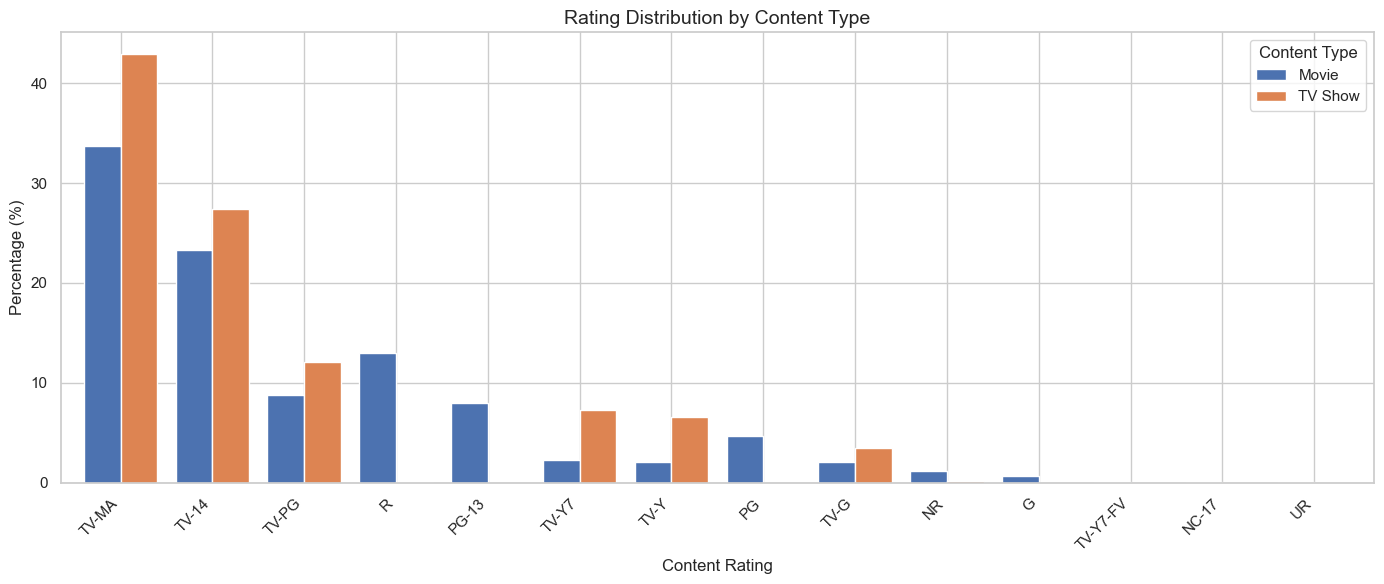

In [8]:
# Visualize rating distribution by content type
ax = rating_comparison.plot(
    kind='bar',
    figsize=(14, 6),
    width=0.8
)

plt.title('Rating Distribution by Content Type', fontsize=14)
plt.xlabel('Content Rating')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Content Type')
plt.tight_layout()
plt.show()

#### Key Findings

The comparison of content ratings across Movies and TV Shows reveals several differences in catalog composition:

1. **TV-MA is the dominant rating category** for both Movies and TV Shows, representing 33.66% and 42.92% of each content type, respectively.
2. **TV-14 is the second most common rating** across both content types, accounting for 23.29% of Movies and 27.38% of TV Shows.
3. **TV-Y and TV-Y7 ratings have a higher representation in TV Shows**, suggesting a relatively larger catalog share of television content classified for younger audiences.
4. **Movie-specific rating categories such as R, PG, and PG-13 are more represented in Movies**, reflecting differences between film and television rating classification systems.

### Genre Composition by Content Type

This subsection compares the most frequently represented genre labels across Movies and TV Shows to identify differences in catalog composition.

In [9]:
# Split genre labels into individual entries
genre_by_type = df[['type', 'listed_in']].copy()

genre_by_type['genre'] = genre_by_type['listed_in'].str.split(',')
genre_by_type = genre_by_type.explode('genre')

genre_by_type['genre'] = genre_by_type['genre'].str.strip()

# Count genre occurrences by content type
genre_type_counts = (
    genre_by_type
    .groupby(['type', 'genre'])
    .size()
    .reset_index(name='title_count')
)

# Get top 10 genres for each content type
top_movie_genres = (
    genre_type_counts[genre_type_counts['type'] == 'Movie']
    .nlargest(10, 'title_count')
)

top_tv_genres = (
    genre_type_counts[genre_type_counts['type'] == 'TV Show']
    .nlargest(10, 'title_count')
)

display(top_movie_genres)
display(top_tv_genres)

,type,genre,title_count
11,Movie,International Movies,2751
7,Movie,Dramas,2423
4,Movie,Comedies,1673
6,Movie,Documentaries,869
0,Movie,Action & Adventure,859
10,Movie,Independent Movies,755
2,Movie,Children & Family Movies,641
15,Movie,Romantic Movies,616
19,Movie,Thrillers,575
14,Movie,Music & Musicals,375


,type,genre,title_count
25,TV Show,International TV Shows,1348
35,TV Show,TV Dramas,761
34,TV Show,TV Comedies,573
23,TV Show,Crime TV Shows,469
26,TV Show,Kids' TV,448
24,TV Show,Docuseries,394
29,TV Show,Romantic TV Shows,370
28,TV Show,Reality TV,255
21,TV Show,British TV Shows,252
20,TV Show,Anime Series,174


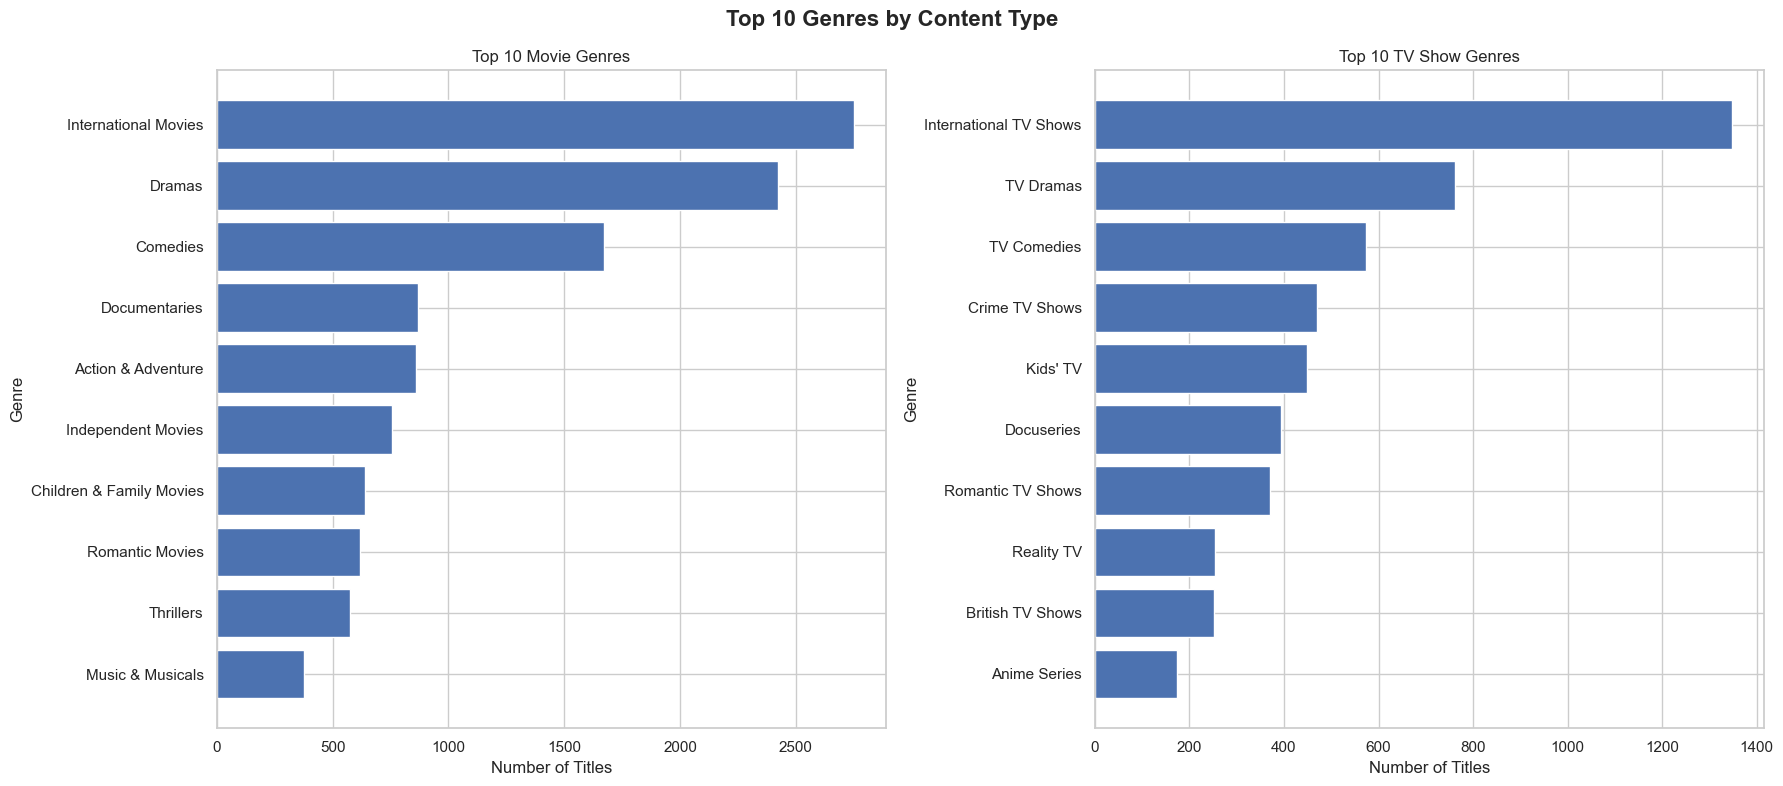

In [10]:
# Combine top 10 genres for visualization
top_genres_combined = pd.concat([
    top_movie_genres,
    top_tv_genres
])

# Create side-by-side charts
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# Movie genres
movie_plot = top_movie_genres.sort_values('title_count')

axes[0].barh(
    movie_plot['genre'],
    movie_plot['title_count']
)

axes[0].set_title('Top 10 Movie Genres')
axes[0].set_xlabel('Number of Titles')
axes[0].set_ylabel('Genre')

# TV Show genres
tv_plot = top_tv_genres.sort_values('title_count')

axes[1].barh(
    tv_plot['genre'],
    tv_plot['title_count']
)

axes[1].set_title('Top 10 TV Show Genres')
axes[1].set_xlabel('Number of Titles')
axes[1].set_ylabel('Genre')

plt.suptitle(
    'Top 10 Genres by Content Type',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

#### Key Findings

The genre comparison reveals distinct patterns in the representation of Movies and TV Shows:

1. **International Movies, Dramas, and Comedies dominate Movie genre representation**, with 2,751, 2,423, and 1,673 occurrences, respectively.
2. **International TV Shows, TV Dramas, and TV Comedies lead TV Show genre representation**, with 1,348, 761, and 573 occurrences, respectively.
3. **Children & Family Movies and Kids' TV appear prominently in their respective content types**, indicating the presence of family-oriented and children's content across both formats.
4. **Documentaries and Action & Adventure are prominent Movie categories**, while Crime TV Shows and Docuseries are among the leading TV Show categories.

These patterns describe genre representation within the catalog and should not be interpreted as direct indicators of audience demand or viewing preferences.

### Geographic Content Representation

This subsection examines the geographic distribution of Netflix content by comparing the representation of Movies and TV Shows across the most frequently represented countries.

The analysis aims to identify differences in content type composition among the leading countries represented in the catalog.

In [11]:
# Select records with available country information
country_data = df.dropna(subset=['country']).copy()

# Count titles by country and content type
country_type_counts = (
    country_data
    .groupby(['country', 'type'])
    .size()
    .unstack(fill_value=0)
)

# Calculate total titles per country
country_type_counts['Total'] = (
    country_type_counts['Movie'] +
    country_type_counts['TV Show']
)

# Select top 10 countries by total titles
top_countries = (
    country_type_counts
    .sort_values('Total', ascending=False)
    .head(10)
)

display(top_countries)

type,Movie,TV Show,Total
country,,,
United States,2395,845,3240
India,975,81,1056
United Kingdom,387,251,638
Pakistan,71,349,420
Canada,187,84,271
Japan,87,172,259
South Korea,49,165,214
France,148,65,213
Spain,129,53,182


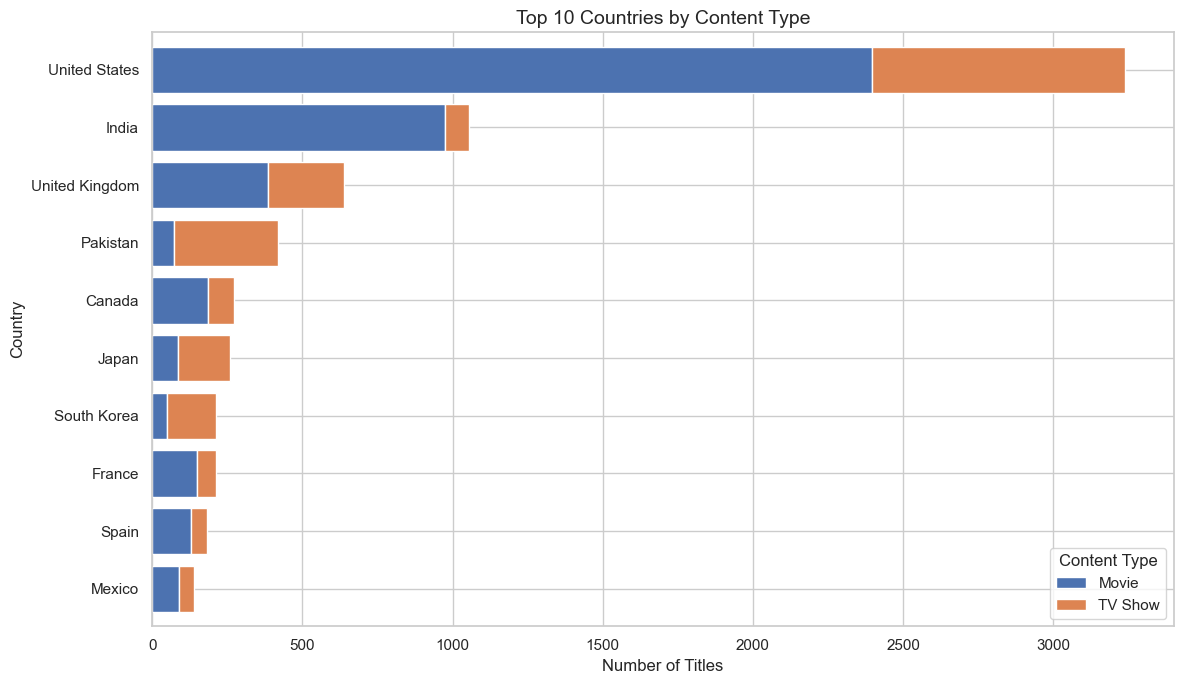

In [12]:
# Prepare data for visualization
country_plot = top_countries[['Movie', 'TV Show']]

country_plot.plot(
    kind='barh',
    stacked=True,
    figsize=(12, 7),
    width=0.8
)

plt.title(
    'Top 10 Countries by Content Type',
    fontsize=14
)

plt.xlabel('Number of Titles')
plt.ylabel('Country')
plt.gca().invert_yaxis()
plt.legend(title='Content Type')

plt.tight_layout()
plt.show()

#### Key Findings

The geographic comparison reveals substantial differences in content type representation across the leading countries:

1. **The United States has the largest catalog representation**, with 3,240 titles, consisting of 2,395 Movies and 845 TV Shows.
2. **India's catalog representation is strongly concentrated in Movies**, which account for approximately 92.33% of its recorded titles.
3. **Pakistan has a notably higher representation of TV Shows**, accounting for approximately 83.10% of its recorded titles.
4. **Japan and South Korea also show relatively high TV Show proportions**, at approximately 66.41% and 77.10%, respectively.
5. **The United Kingdom has a more balanced content type composition** compared with the United States and India.

These findings highlight geographic differences in catalog composition. However, they should not be interpreted as direct evidence of local audience preferences or production strategies.

### Release Year Trends

This subsection examines the distribution of Netflix titles by release year and compares the release year patterns between Movies and TV Shows.

The analysis aims to identify periods with the highest catalog representation and understand how the release year distribution differs across content types.

In [13]:
# Count titles by release year and content type
release_year_type = (
    df.groupby(['release_year', 'type'])
    .size()
    .unstack(fill_value=0)
)

# Calculate total titles per release year
release_year_type['Total'] = (
    release_year_type['Movie'] +
    release_year_type['TV Show']
)

# Identify the top 10 release years
top_release_years = (
    release_year_type
    .sort_values('Total', ascending=False)
    .head(10)
    .sort_index()
)

display(top_release_years)

type,Movie,TV Show,Total
release_year,,,
2012,173,63,236
2013,225,61,286
2014,263,88,351
2015,396,159,555
2016,658,243,901
2017,765,265,1030
2018,766,378,1144
2019,632,397,1029
2020,517,436,953


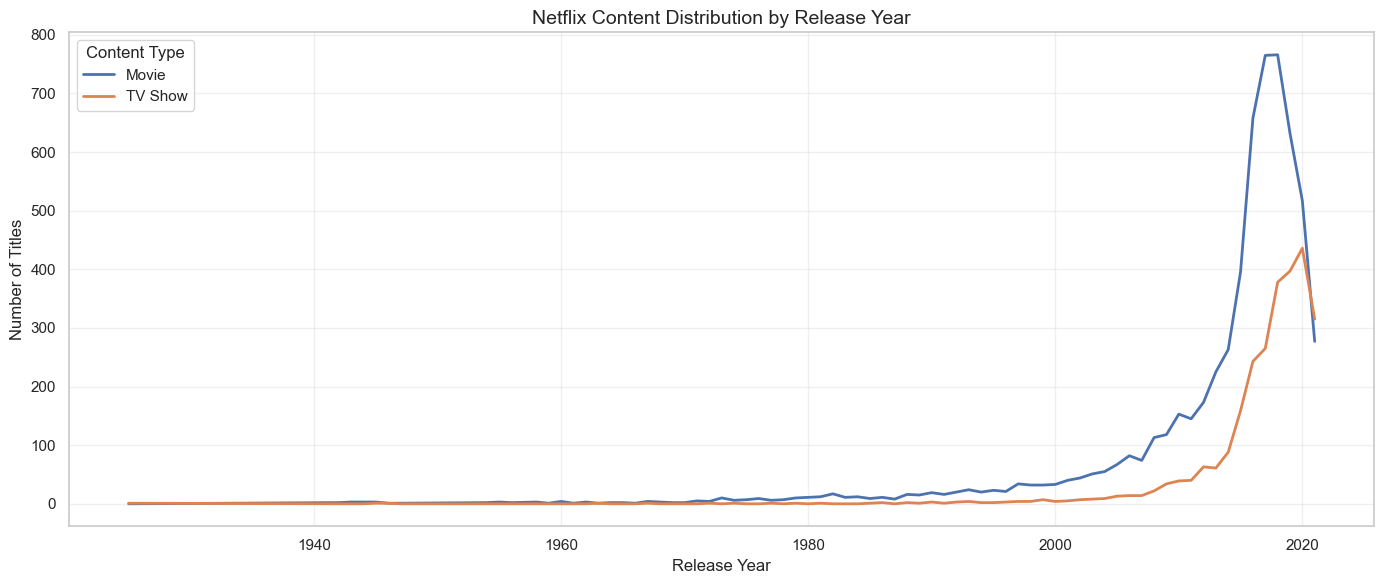

In [14]:
# Plot release year trends by content type
plt.figure(figsize=(14, 6))

plt.plot(
    release_year_type.index,
    release_year_type['Movie'],
    label='Movie',
    linewidth=2
)

plt.plot(
    release_year_type.index,
    release_year_type['TV Show'],
    label='TV Show',
    linewidth=2
)

plt.title(
    'Netflix Content Distribution by Release Year',
    fontsize=14
)

plt.xlabel('Release Year')
plt.ylabel('Number of Titles')
plt.legend(title='Content Type')
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

#### Key Findings

The release year analysis reveals several patterns in the distribution of Netflix content:

1. **2018 represents the highest release year concentration**, with 1,144 titles, consisting of 766 Movies and 378 TV Shows.
2. **Movie representation peaked in 2018**, with 766 titles, while TV Show representation reached its highest point in 2020, with 436 titles.
3. **Movie counts declined after 2018**, while TV Show counts continued to increase until 2020.
4. **TV Shows outnumbered Movies in 2021**, with 315 and 277 titles, respectively, indicating a shift in the composition of the catalog for that release year.

These patterns describe the release year distribution of titles represented in the dataset. They do not directly measure Netflix's annual production output or business performance.

#### Recent Release Year Distribution (2000–2021)

This visualization focuses on titles released between 2000 and 2021 to provide a clearer view of the more recent release year distribution.

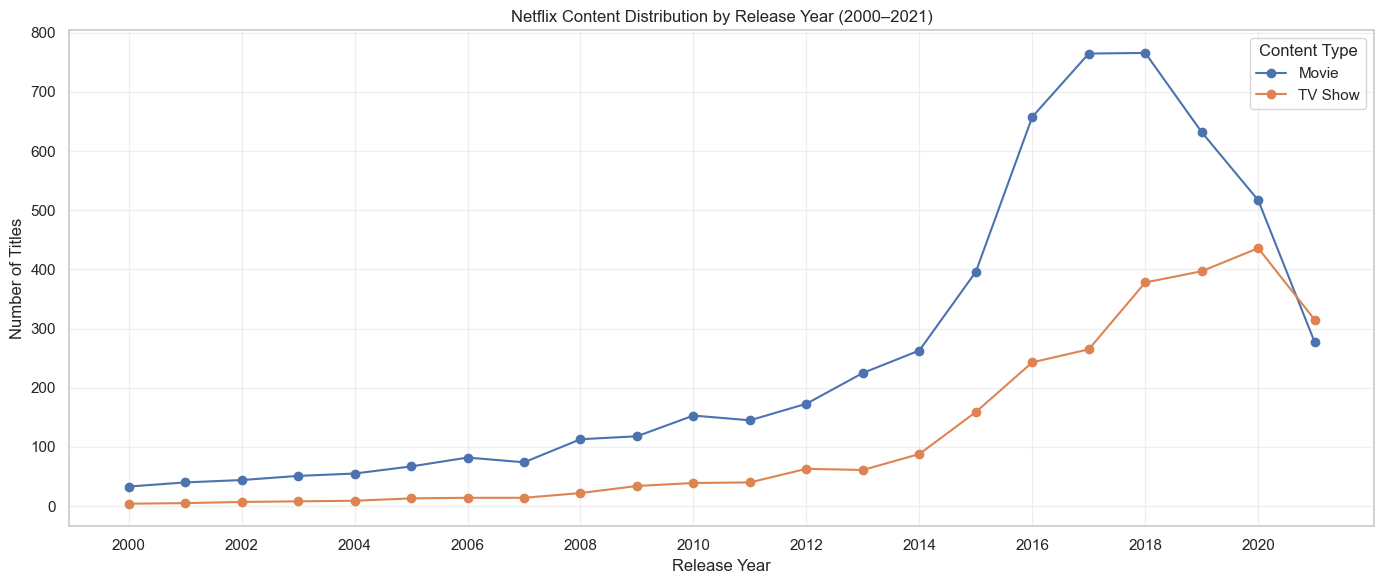

In [15]:
# Filter release years from 2000 to 2021
recent_release_years = release_year_type.loc[2000:2021]

# Plot recent release year distribution
plt.figure(figsize=(14, 6))

plt.plot(
    recent_release_years.index,
    recent_release_years['Movie'],
    marker='o',
    label='Movie'
)

plt.plot(
    recent_release_years.index,
    recent_release_years['TV Show'],
    marker='o',
    label='TV Show'
)

plt.title('Netflix Content Distribution by Release Year (2000–2021)')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles')
plt.xticks(range(2000, 2022, 2))
plt.legend(title='Content Type')
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

#### Key Findings

The focused release year analysis (2000–2021) highlights several patterns in the Netflix content catalog:

1. **Movies maintained higher representation than TV Shows for most of the observed period**, particularly between 2015 and 2018.
2. **Movie representation increased substantially between 2015 and 2017**, reaching its highest point in 2018.
3. **TV Show representation experienced notable growth after 2015**, reaching its highest point in 2020.
4. **The difference between Movies and TV Shows narrowed in recent release years**, with TV Shows exceeding Movies in 2021.
5. **The decline in title counts in 2021 should be interpreted cautiously**, as the dataset only covers release years up to 2021.

These observations describe catalog representation by release year and do not directly measure annual production output or viewing performance.

## Integrated Business Insights

This section synthesizes the findings from the previous analytical sections to identify broader patterns and potential business implications within the Netflix content catalog.

Rather than examining each dimension independently, this section connects content type, geographic representation, ratings, genres, and release year distribution to develop a more comprehensive understanding of the catalog.

The insights are intended to support content portfolio evaluation and identify areas for further strategic investigation.

### **1. Content Portfolio Structure**

The Netflix content catalog is predominantly composed of Movies, representing 69.69% of all titles, while TV Shows account for the remaining 30.31%.

This indicates that Movies have a larger representation in the analyzed catalog. However, the difference in content type distribution should be considered alongside other dimensions, particularly geographic representation and genre composition.

**Business Implication:**

The catalog distribution provides a useful baseline for evaluating the balance between Movies and TV Shows. Further portfolio evaluation could examine whether the current composition aligns with content strategy objectives and the intended diversity of the catalog.

**Data Limitation:**

The distribution reflects the available catalog metadata and does not indicate audience demand, viewing performance, profitability, or the optimal proportion of each content type.

### **2. Geographic Content Representation**

The geographic analysis reveals substantial differences in content type representation across countries.

The United States has the largest representation in the catalog, with 3,240 titles. India follows with 1,056 titles, although its catalog representation is strongly concentrated in Movies (92.33%).

In contrast, Pakistan has a higher proportion of TV Shows (83.10%). Japan and South Korea also demonstrate relatively high TV Show representation, accounting for 66.41% and 77.10% of their respective country totals.

**Business Implication:**

These differences highlight the importance of evaluating geographic content representation beyond total title counts. A country with fewer titles may still have a distinct content composition that contributes to catalog diversity.

Netflix could use these patterns as a starting point for further evaluation of regional catalog representation and content portfolio diversity.

**Data Limitation:**

Country-level representation does not establish local audience preferences, content demand, production volume, or regional business performance. The dataset also contains 287 titles without country information, which are excluded from this geographic analysis.

### **3. Content Classification and Genre Positioning**

The rating analysis indicates that TV-MA is the most frequently represented classification, accounting for 36.47% of the catalog, followed by TV-14 at 24.53%.

The genre analysis identifies International Movies (31.31%), Dramas (27.58%), and Comedies (19.04%) as the most frequently represented genre labels.

Differences also emerge across content types. TV Shows have a higher proportion of TV-MA classifications (42.92%) compared with Movies (33.66%). Meanwhile, TV-Y and TV-Y7 classifications are relatively more represented in TV Shows, while movie-specific classifications such as R and PG-13 are more prominent in Movies.

**Business Implication:**

The distribution of ratings and genres provides a useful overview of the catalog's content positioning and classification diversity.

These findings could support further evaluation of content portfolio balance, genre representation, and age-classification coverage across Movies and TV Shows.

**Data Limitation:**

Content ratings represent classification categories rather than actual audience demographics or viewing preferences. Similarly, genre frequencies indicate catalog representation, not audience demand or content popularity. A single title may also be associated with multiple genre labels.

### **4. Content Classification and Genre Positioning**

The rating analysis indicates that TV-MA is the most frequently represented classification, accounting for 36.47% of the catalog, followed by TV-14 at 24.53%.

The genre analysis identifies International Movies (31.31%), Dramas (27.58%), and Comedies (19.04%) as the most frequently represented genre labels.

Differences also emerge across content types. TV Shows have a higher proportion of TV-MA classifications (42.92%) compared with Movies (33.66%). Meanwhile, TV-Y and TV-Y7 classifications are relatively more represented in TV Shows, while movie-specific classifications such as R and PG-13 are more prominent in Movies.

**Business Implication:**

The distribution of ratings and genres provides a useful overview of the catalog's content positioning and classification diversity.

These findings could support further evaluation of content portfolio balance, genre representation, and age-classification coverage across Movies and TV Shows.

**Data Limitation:**

Content ratings represent classification categories rather than actual audience demographics or viewing preferences. Similarly, genre frequencies indicate catalog representation, not audience demand or content popularity. A single title may also be associated with multiple genre labels.

## Business Recommendations

Based on the integrated findings, several recommendations can be considered to support content portfolio evaluation and improve the understanding of Netflix's catalog composition.

The recommendations focus on portfolio balance, geographic representation, content classification, and release year distribution. Additional performance data would be required before making investment or content acquisition decisions.

### **1. Evaluate Content Type Balance**

**Finding:**

Movies account for 69.69% of the analyzed catalog, while TV Shows represent 30.31%.

**Recommendation:**

Evaluate the existing balance between Movies and TV Shows to determine whether the current catalog composition aligns with content portfolio objectives. Consider examining the contribution of each content type using additional performance indicators.

**Additional Data Required:**

- Viewing hours by content type.
- Number of unique viewers.
- Content acquisition and production costs.
- Revenue or subscription contribution by content type.

### **2. Review Geographic Content Representation**

**Finding:**

The United States has the largest catalog representation, while countries such as India, Pakistan, Japan, and South Korea demonstrate different Movie and TV Show compositions.

**Recommendation:**

Review geographic content representation to understand how regional catalogs contribute to overall content diversity. Further investigation could focus on identifying underrepresented regions and evaluating opportunities to improve catalog coverage.

**Additional Data Required:**

- Regional viewing hours and audience engagement.
- Country-level content acquisition costs.
- Regional subscription and revenue data.
- Content availability by country.

### **3. Evaluate Genre and Rating Diversity**

**Finding:**

TV-MA is the most frequently represented rating category, while International Movies, Dramas, and Comedies are the leading genre labels.

**Recommendation:**

Assess the diversity of genre representation and rating classifications across Movies and TV Shows. This evaluation could help identify potential gaps in the existing catalog and support a more balanced content portfolio.

**Additional Data Required:**

- Viewing performance by genre.
- Audience distribution by age classification, where lawfully and appropriately available.
- Engagement metrics by content category.
- Content performance across different audience segments.

### **4. Monitor Catalog Release Year Distribution**

**Finding:**

The largest release year concentration occurred in 2018, while the composition of Movies and TV Shows changed in the more recent release years covered by the dataset.

**Recommendation:**

Monitor the distribution of recently released and older titles to evaluate catalog recency and maintain a diverse content library. Further analysis should consider title availability and performance over time.

**Additional Data Required:**

- Content availability and removal dates.
- Viewing performance by release year.
- Content licensing duration.
- Acquisition and renewal costs.

## Analysis Limitations

Although this report provides an integrated overview of Netflix's content catalog, several limitations should be considered when interpreting the findings.

1. **Metadata-Based Analysis:** The dataset contains content metadata rather than actual business performance metrics. Therefore, this analysis cannot directly measure audience preferences, viewing behavior, engagement, revenue, profitability, or content performance.

2. **Missing Values:** The cleaned dataset still contains missing values, particularly in the `director` column (2,587 records) and the `country` column (287 records). These missing values may affect analyses involving geographic representation and director information.

3. **Multi-Label Genre Classification:** Each title may be associated with multiple genres. Consequently, genre counts are not mutually exclusive, and genre percentages may exceed 100% when combined.

4. **Rating Classification Differences:** Movie and TV Show ratings use classification categories that are not entirely equivalent. Comparisons between content types should therefore be interpreted descriptively rather than as direct measures of audience suitability.

5. **Release Year Coverage:** The dataset contains release years up to 2021. As a result, the analysis cannot describe release year patterns beyond that period. The lower number of titles in 2021 should not be interpreted as evidence of declining content production or investment.

6. **Dataset Coverage:** The findings reflect the records available in the dataset and may not represent the complete or current Netflix catalog across all regions and periods.

These limitations should be considered before using the findings to support strategic or investment decisions.

## Conclusion

This analysis provides an integrated overview of Netflix's content catalog through content type, geographic representation, release year distribution, ratings, and genre composition.

Several key findings emerge from the analysis:

1. **Content Portfolio:** Movies account for 69.69% of the dataset, while TV Shows represent 30.31%, indicating that movies have a larger share of catalog records.

2. **Geographic Representation:** The United States is the most represented country, accounting for 38.12% of records with available country information. The top five countries collectively represent 66.18% of those records.

3. **Content Classification:** TV-MA is the most common rating category, while International Movies, Dramas, and Comedies are the most frequently represented genre labels.

4. **Release Year Distribution:** Titles released in 2018 form the largest annual group, with 1,144 records. The distribution of Movies and TV Shows also varies across release years.

Overall, the findings provide a structured understanding of Netflix's catalog composition and highlight areas that may warrant further evaluation, including content type balance, geographic representation, genre diversity, and catalog recency.

However, metadata alone is insufficient to determine content performance or establish the effectiveness of business strategies. Further analysis using viewing, engagement, revenue, cost, and regional audience data would be necessary to develop stronger business conclusions.